In [1]:
pip install torchvision

Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("Device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("Current device:", torch.cuda.current_device())
    print("Device name:", torch.cuda.get_device_name(torch.cuda.current_device()))
else:
    print("No CUDA device detected.")
    

CUDA available: True
CUDA version: 13.0
Device count: 1
Current device: 0
Device name: NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [4]:
from datasets import load_dataset, concatenate_datasets

pope_dataset = load_dataset("MM-Hallu/POPE")
main_split = pope_dataset[list(pope_dataset.keys())[0]]

# 100-sample slice for fast adversarial evaluation
eval_split = main_split.filter(lambda x: x["category"] == "adversarial").select(range(100))
# Pool for training
train_pool = main_split.filter(lambda x: x["category"] == "random")

/home/virendra2605/Documents/inter-iit-cvps/task-b-vlm/venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

model_id = "HuggingFaceTB/SmolVLM-500M-Instruct"

processor = AutoProcessor.from_pretrained(model_id)

model = AutoModelForImageTextToText.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto"
)

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1147.45it/s]


In [6]:
from tqdm import tqdm

def evaluate_model(eval_model, split, desc="Evaluating"):
    eval_model.eval()
    y_true, y_pred = [], []
    
    for sample in tqdm(split, desc=desc):
        image = sample["image"]
        expected = sample["answer"].lower().strip()
        
        # Native Qwen chat template
        messages = [{"role": "user", "content": [
            {"type": "image"},
            {"type": "text", "text": f"{sample['question']}\nAnswer yes or no."}
        ]}]
        prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        
        inputs = processor(text=[prompt], images=[image], return_tensors="pt").to(eval_model.device)
        
        with torch.no_grad():
            outputs = eval_model.generate(**inputs, max_new_tokens=5)
            
        # Qwen outputs the full sequence; strip the input tokens to get just the answer
        generated_ids_trimmed = [out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, outputs)]
        response = processor.batch_decode(generated_ids_trimmed, skip_special_tokens=True)[0].lower()
        
        pred = "yes" if "yes" in response else "no"
        y_true.append(1 if expected == "yes" else 0)
        y_pred.append(1 if pred == "yes" else 0)

    tp = sum(1 for yt, yp in zip(y_true, y_pred) if yt == 1 and yp == 1)
    tn = sum(1 for yt, yp in zip(y_true, y_pred) if yt == 0 and yp == 0)
    fp = sum(1 for yt, yp in zip(y_true, y_pred) if yt == 0 and yp == 1)
    
    acc = (tp + tn) / len(y_true)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    yes_ratio = sum(y_pred) / len(y_pred)
    
    print(f"\n--- {desc} Metrics ---")
    print(f"Accuracy: {acc:.2f} | FPR: {fpr:.2f} | Yes%: {yes_ratio:.2f}")



In [7]:
# Run baseline
baseline = evaluate_model(model, eval_split, "Baseline")


Baseline: 100%|██████████| 100/100 [00:27<00:00,  3.65it/s]


--- Baseline Metrics ---
Accuracy: 0.81 | FPR: 0.20 | Yes%: 0.51


In [8]:
from peft import prepare_model_for_kbit_training, LoraConfig, get_peft_model

# 1. Attach LoRA
model = prepare_model_for_kbit_training(model)
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    task_type="CAUSAL_LM"
)
peft_model = get_peft_model(model, lora_config)
peft_model.print_trainable_parameters()

# 2. Strict 50/50 Data Balance (100 Yes / 100 No)
yes_bucket = train_pool.filter(lambda x: x["answer"].lower().strip() == "yes")
no_bucket = train_pool.filter(lambda x: x["answer"].lower().strip() == "no")

balanced_train = concatenate_datasets([
    yes_bucket.select(range(100)), 
    no_bucket.select(range(100))
]).shuffle(seed=42)

trainable params: 2,228,224 || all params: 509,710,528 || trainable%: 0.4372


In [9]:
# Clear residual PyTorch caching allocator pools
import gc
gc.collect()
torch.cuda.empty_cache()

# Trade minimal compute for significant VRAM reduction
peft_model.gradient_checkpointing_enable()
peft_model.enable_input_require_grads()

In [10]:

import torch.optim as optim
from peft import get_peft_model_state_dict, set_peft_model_state_dict

optimizer = optim.AdamW(peft_model.parameters(), lr=2e-4)
peft_model.train()

best_loss = float('inf')
best_weights = None
patience = 0

print("Starting LoRA training...")

for step, sample in enumerate(balanced_train):
    image = sample["image"]
    expected = sample["answer"].lower().strip()
    
    messages = [{"role": "user", "content": [
        {"type": "image"},
        {"type": "text", "text": f"{sample['question']}\nAnswer yes or no."}
    ]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    
    base_inputs = processor(text=[prompt], images=[image], return_tensors="pt")
    prompt_length = base_inputs["input_ids"].shape[1]
    
    full_prompt = prompt + expected
    inputs = processor(text=[full_prompt], images=[image], return_tensors="pt").to(peft_model.device)
    
    labels = inputs["input_ids"].clone()
    labels[0, :prompt_length] = -100
    inputs["labels"] = labels
    
    loss = peft_model(**inputs).loss
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    
    # Extract ONLY the LoRA adapter weights, clone to CPU
    if loss.item() < best_loss:
        best_loss = loss.item()
        best_weights = {k: v.cpu().clone() for k, v in get_peft_model_state_dict(peft_model).items()}
        patience = 0
    else:
        patience += 1
        
    if step % 20 == 0:
        print(f"Step {step} | Loss: {loss.item():.4f}")
    if patience >= 40:
        print("Early stopping triggered.")
        break

print("Restoring best weights...")
# Load ONLY the LoRA adapters back in
set_peft_model_state_dict(peft_model, best_weights)
print("Done.")

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Starting LoRA training...
Step 0 | Loss: 17.2730


/home/virendra2605/Documents/inter-iit-cvps/task-b-vlm/venv/lib64/python3.14/site-packages/peft/utils/other.py:1496: UserWarning: Unable to fetch remote file due to the following error [Errno 104] Connection reset by peer - silently ignoring the lookup for the file config.json in HuggingFaceTB/SmolVLM-500M-Instruct.
  warnings.warn(
/home/virendra2605/Documents/inter-iit-cvps/task-b-vlm/venv/lib64/python3.14/site-packages/peft/utils/save_and_load.py:438: UserWarning: Could not find a config file in HuggingFaceTB/SmolVLM-500M-Instruct - will assume that the vocabulary was not modified.
  warnings.warn(


Step 20 | Loss: 1.2473
Step 40 | Loss: 0.0862
Step 60 | Loss: 0.0766
Step 80 | Loss: 0.0026
Step 100 | Loss: 0.0048
Step 120 | Loss: 0.1440
Early stopping triggered.
Restoring best weights...
Done.


In [11]:

evaluate_model(peft_model, eval_split, "LoRA Fine-tuned")


LoRA Fine-tuned: 100%|██████████| 100/100 [01:22<00:00,  1.21it/s]


--- LoRA Fine-tuned Metrics ---
Accuracy: 0.81 | FPR: 0.16 | Yes%: 0.47


In [13]:
strict_instruction = "Look only at the image. If the object is not clearly visible, you must say no. Answer yes or no."

In [14]:
# Cell 8
print("--- Zero-Shot Prompt Intervention Test ---")

# Aggressive anti-hallucination prompt
# strict_instruction = "Answer yes or no. Look extremely closely at the image. Do not guess. Only answer yes if the object is physically present."

# Temporarily shut off the LoRA weights to test the raw base model
with peft_model.disable_adapter():
    peft_model.eval()
    y_true, y_pred = [], []
    
    for sample in tqdm(eval_split, desc="Evaluating Strict Prompt (Base)"):
        image = sample["image"]
        expected = sample["answer"].lower().strip()
        
        messages = [{"role": "user", "content": [
            {"type": "image"},
            {"type": "text", "text": f"{sample['question']}\n{strict_instruction}"}
        ]}]
        prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        
        inputs = processor(text=[prompt], images=[image], return_tensors="pt").to(peft_model.device)
        
        with torch.no_grad():
            outputs = peft_model.generate(**inputs, max_new_tokens=5)
            
        generated_ids_trimmed = [out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, outputs)]
        response = processor.batch_decode(generated_ids_trimmed, skip_special_tokens=True)[0].lower()
        
        pred = "yes" if "yes" in response else "no"
        y_true.append(1 if expected == "yes" else 0)
        y_pred.append(1 if pred == "yes" else 0)

    # Calculate metrics
    tp = sum(1 for yt, yp in zip(y_true, y_pred) if yt == 1 and yp == 1)
    tn = sum(1 for yt, yp in zip(y_true, y_pred) if yt == 0 and yp == 0)
    fp = sum(1 for yt, yp in zip(y_true, y_pred) if yt == 0 and yp == 1)
    
    acc = (tp + tn) / len(y_true)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    yes_ratio = sum(y_pred) / len(y_pred)
    
    print(f"\nAccuracy: {acc:.2f} | FPR: {fpr:.2f} | Yes%: {yes_ratio:.2f}")

--- Zero-Shot Prompt Intervention Test ---


Evaluating Strict Prompt (Base): 100%|██████████| 100/100 [01:18<00:00,  1.27it/s]


Accuracy: 0.82 | FPR: 0.18 | Yes%: 0.50


In [16]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 2.2 MB/s  0:00:05 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 5.3 MB/s  0:00:01m0:00:0100:01
Using cached kiwisolver-1.5.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (1.5 MB)
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


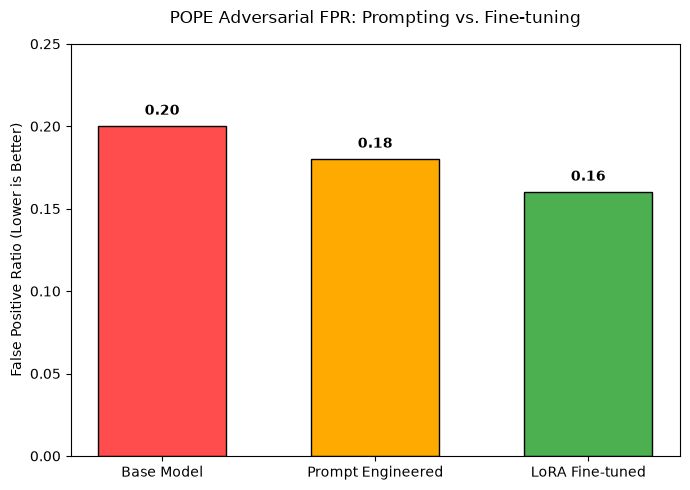

In [17]:
# Cell 9: Report Visualization
import matplotlib.pyplot as plt

methods = ['Base Model', 'Prompt Engineered', 'LoRA Fine-tuned']
fpr_values = [0.20, 0.18, 0.16]
colors = ['#ff4c4c', '#ffaa00', '#4caf50'] # Red, Orange, Green

plt.figure(figsize=(7, 5))
bars = plt.bar(methods, fpr_values, color=colors, edgecolor='black', width=0.6)

plt.title('POPE Adversarial FPR: Prompting vs. Fine-tuning', pad=15)
plt.ylabel('False Positive Ratio (Lower is Better)')
plt.ylim(0, 0.25) 

# Auto-label the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f"{yval:.2f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Cell 10: Comprehensive Evaluation & Metrics Report
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

def compute_comprehensive_metrics(y_true, y_pred, desc="Model"):
    # Raw counts
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    total = tp + tn + fp + fn
    
    # Core Metrics
    accuracy = (tp + tn) / total
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    yes_ratio = sum(y_pred) / total if total > 0 else 0.0
    
    # Supplementary Metrics (Precision, Recall, F1 for the positive "Yes" class)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    
    print(f"================ {desc} ================")
    print(f"Overall Accuracy : {accuracy:.4f}")
    print(f"False Positive R.: {fpr:.4f}  <-- (Direct hallucination indicator)")
    print(f"Yes/No Bias      : {yes_ratio:.4f}  <-- (Fraction of 'Yes' predictions)")
    print(f"Precision        : {precision:.4f}")
    print(f"Recall           : {recall:.4f}")
    print(f"F1 Score         : {f1:.4f}")
    print(f"Confusion Matrix : TN={tn}, FP={fp}, FN={fn}, TP={tp}\n")

# Run on your evaluation sets to dump the final stats for your report


In [20]:
# Cell 10: Final Comprehensive Evaluation Report
import torch
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

# 1. Helper to run inference and return the raw arrays
def get_predictions(eval_model, split, instruction="Answer yes or no."):
    eval_model.eval()
    y_true, y_pred = [], []
    
    for sample in tqdm(split, desc=f"Evaluating ({instruction[:20]}...)"):
        image = sample["image"]
        expected = sample["answer"].lower().strip()
        
        messages = [{"role": "user", "content": [
            {"type": "image"},
            {"type": "text", "text": f"{sample['question']}\n{instruction}"}
        ]}]
        prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = processor(text=[prompt], images=[image], return_tensors="pt").to(eval_model.device)
        
        with torch.no_grad():
            outputs = eval_model.generate(**inputs, max_new_tokens=5)
            
        generated_ids_trimmed = [out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, outputs)]
        response = processor.batch_decode(generated_ids_trimmed, skip_special_tokens=True)[0].lower()
        
        pred = "yes" if "yes" in response else "no"
        y_true.append(1 if expected == "yes" else 0)
        y_pred.append(1 if pred == "yes" else 0)
        
    return y_true, y_pred

# 2. The comprehensive metric calculator
def compute_comprehensive_metrics(y_true, y_pred, desc="Model"):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    total = tp + tn + fp + fn
    
    accuracy = (tp + tn) / total
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    yes_ratio = sum(y_pred) / total if total > 0 else 0.0
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
    
    print(f"\n================ {desc} ================")
    print(f"Overall Accuracy : {accuracy:.4f}")
    print(f"False Positive R.: {fpr:.4f}  <-- (Direct hallucination indicator)")
    print(f"Yes/No Bias      : {yes_ratio:.4f}  <-- (Fraction of 'Yes' predictions)")
    print(f"Precision        : {precision:.4f}")
    print(f"Recall           : {recall:.4f}")
    print(f"F1 Score         : {f1:.4f}")
    print(f"Confusion Matrix : TN={tn}, FP={fp}, FN={fn}, TP={tp}\n")

# 3. Execution Block
print("--- GENERATING FINAL REPORT METRICS ---")

# Base Model
with peft_model.disable_adapter():
    y_true_base, y_pred_base = get_predictions(peft_model, eval_split)
    compute_comprehensive_metrics(y_true_base, y_pred_base, "Base Model (Zero-Shot)")

# Base Model + Prompt Engineering
with peft_model.disable_adapter():
    strict_instruction = "Look only at the image. If the object is not clearly visible, you must say no. Answer yes or no."
    y_true_prompt, y_pred_prompt = get_predictions(peft_model, eval_split, instruction=strict_instruction)
    compute_comprehensive_metrics(y_true_prompt, y_pred_prompt, "Base Model + Strict Prompt")

# LoRA Fine-Tuned Model
y_true_lora, y_pred_lora = get_predictions(peft_model, eval_split)
compute_comprehensive_metrics(y_true_lora, y_pred_lora, "LoRA Fine-tuned Model")

--- GENERATING FINAL REPORT METRICS ---


Evaluating (Answer yes or no....):   0%|          | 0/100 [00:00<?, ?it/s]

Evaluating (Answer yes or no....): 100%|██████████| 100/100 [01:15<00:00,  1.32it/s]



================ Base Model (Zero-Shot) ================
Overall Accuracy : 0.8100
False Positive R.: 0.2000  <-- (Direct hallucination indicator)
Yes/No Bias      : 0.5100  <-- (Fraction of 'Yes' predictions)
Precision        : 0.8039
Recall           : 0.8200
F1 Score         : 0.8119
Confusion Matrix : TN=40, FP=10, FN=9, TP=41



Evaluating (Look only at the ima...): 100%|██████████| 100/100 [01:21<00:00,  1.23it/s]



================ Base Model + Strict Prompt ================
Overall Accuracy : 0.8200
False Positive R.: 0.1800  <-- (Direct hallucination indicator)
Yes/No Bias      : 0.5000  <-- (Fraction of 'Yes' predictions)
Precision        : 0.8200
Recall           : 0.8200
F1 Score         : 0.8200
Confusion Matrix : TN=41, FP=9, FN=9, TP=41



Evaluating (Answer yes or no....): 100%|██████████| 100/100 [01:25<00:00,  1.17it/s]


================ LoRA Fine-tuned Model ================
Overall Accuracy : 0.8100
False Positive R.: 0.1600  <-- (Direct hallucination indicator)
Yes/No Bias      : 0.4700  <-- (Fraction of 'Yes' predictions)
Precision        : 0.8298
Recall           : 0.7800
F1 Score         : 0.8041
Confusion Matrix : TN=42, FP=8, FN=11, TP=39

